# University Finder: Which University Fits You Best?

**Question:** Given what a student cares about (reputation, jobs, small classes, research, international life) and where they want to study, which universities are the best match, and which ones are similar to a university they already like?

**Data:** QS World University Rankings 2024, official results table (Excel file `qs_2024.xlsx`), real data for 1,498 universities in 104 countries.
https://www.topuniversities.com/world-university-rankings

**Before you run:** put `qs_2024.xlsx` in the same folder as this notebook.

In [1]:
%pip install pandas numpy matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (10, 5)

## 1. Load the data

In [3]:
path = "qs_2024.xlsx" if os.path.exists("qs_2024.xlsx") else "data/qs_2024.xlsx"

# The Excel file has 4 header rows, so we skip them and give our own column names.
cols = ["rank_2024", "rank_2023", "institution", "country_code", "country",
        "size", "focus", "research", "status",
        "ar_score", "ar_rank", "er_score", "er_rank", "fsr_score", "fsr_rank",
        "cpf_score", "cpf_rank", "ifr_score", "ifr_rank", "isr_score", "isr_rank",
        "irn_score", "irn_rank", "ger_score", "ger_rank", "sus_score", "sus_rank",
        "overall_score"]

raw = pd.read_excel(path, header=None, skiprows=4, names=cols)
print("File:", path)
print("Shape:", raw.shape)
raw.head()

File: qs_2024.xlsx
Shape: (1498, 28)


,rank_2024,rank_2023,institution,country_code,country,size,focus,research,status,ar_score,ar_rank,er_score,er_rank,fsr_score,fsr_rank,cpf_score,cpf_rank,ifr_score,ifr_rank,isr_score,isr_rank,irn_score,irn_rank,ger_score,ger_rank,sus_score,sus_rank,overall_score
0,1,1,Massachusetts Institute of Technology (MIT),US,United States,M,CO,VH,B,100.0,4,100.0,2,100.0,16,100.0,4,100.0,56,88.2,128,94.3,58,100.0,4,95.2,51,100
1,2,2,University of Cambridge,UK,United Kingdom,L,FC,VH,A,100.0,3,100.0,4,100.0,14,92.3,68,100.0,64,95.8,85,99.9,7,100.0,6,97.3,33=,99.2
2,3,4,University of Oxford,UK,United Kingdom,L,FC,VH,A,100.0,2,100.0,5,100.0,8,90.6,73,98.2,110,98.2,60,100.0,1,100.0,3,97.8,26=,98.9
3,4,5,Harvard University,US,United States,L,FC,VH,B,100.0,1,100.0,1,98.3,44,100.0,1,84.6,210,66.8,223,100.0,5,100.0,1,96.7,39,98.3
4,5,3,Stanford University,US,United States,L,FC,VH,B,100.0,5,100.0,3,100.0,11,99.9,8,99.9,78,51.2,284,95.8,44,100.0,2,94.4,63,98.1


In [4]:
print(raw.dtypes.head(12))
print()
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print()
print("Examples of rank values:", raw["rank_2024"].astype(str).sample(8, random_state=1).tolist())
print("Examples of overall_score:", raw["overall_score"].astype(str).sample(8, random_state=1).tolist())

rank_2024        object
rank_2023        object
institution      object
country_code     object
country          object
size             object
focus            object
research         object
status           object
ar_score        float64
ar_rank          object
er_score        float64
dtype: object

Missing values per column:
rank_2023     83
size          23
focus          1
research      87
status        45
er_score       1
er_rank        1
fsr_score     24
fsr_rank      24
cpf_score     24
cpf_rank      24
ifr_score    126
ifr_rank     126
isr_score     80
isr_rank      80
irn_score      4
irn_rank       4
ger_score     24
ger_rank      24
sus_score    100
sus_rank     100
dtype: int64

Examples of rank values: ['=91', '=76', '1201-1400', '=328', '951-1000', '851-900', '901-950', '1001-1200']
Examples of overall_score: ['61.6', '65.2', '-', '32.6', '-', '-', '-', '-']


## 2. Clean the data
Problems we found in the raw file:
- ranks are text: `=76` (tie), `1001-1200` (a band), `1401+`
- scores use `-` for "no score", so they are text and not numbers
- sizes, focus, and research levels are codes (`XL`, `FC`, `VH`)
- 896 universities have no overall score (QS only gives a score to the top group)

In [5]:
df = raw.copy()
print("Rows before:", len(df))

# 1. remove duplicates and extra spaces
df["institution"] = df["institution"].astype(str).str.strip()
df["country"] = df["country"].astype(str).str.strip()
df = df.drop_duplicates(subset="institution")

# 2. rank: keep the original text and make a number from the first digits
df["rank_label"] = df["rank_2024"].astype(str)
df["rank_num"] = df["rank_label"].str.extract(r"(\d+)")[0].astype(int)
df["rank_group"] = pd.cut(df["rank_num"], [0, 100, 200, 500, 1000, 5000],
                          labels=["Top 100", "101-200", "201-500", "501-1000", "1000+"])

# 3. scores: "-" and other text become missing values (NaN)
score_cols = [c for c in df.columns if c.endswith("_score")]
for c in score_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 4. readable labels for the codes
df["size_label"] = df["size"].map({"XL": "Extra large", "L": "Large", "M": "Medium", "S": "Small"})
df["focus_label"] = df["focus"].map({"FC": "Full comprehensive", "CO": "Comprehensive",
                                     "FO": "Focused", "SP": "Specialist"})
df["research_label"] = df["research"].map({"VH": "Very high", "HI": "High",
                                           "MD": "Medium", "LO": "Low"})

# 5. keep only the useful columns
keep = (["institution", "country", "rank_label", "rank_num", "rank_group",
         "size_label", "focus_label", "research_label"] + score_cols)
df = df[keep].reset_index(drop=True)

print("Rows after:", len(df))
print("Countries:", df["country"].nunique())
print("Universities with an overall score:", df["overall_score"].notna().sum())
df.head()

Rows before: 1498
Rows after: 1498
Countries: 104
Universities with an overall score: 602


,institution,country,rank_label,rank_num,rank_group,size_label,focus_label,research_label,ar_score,er_score,fsr_score,cpf_score,ifr_score,isr_score,irn_score,ger_score,sus_score,overall_score
0,Massachusetts Institute of Technology (MIT),United States,1,1,Top 100,Medium,Comprehensive,Very high,100.0,100.0,100.0,100.0,100.0,88.2,94.3,100.0,95.2,100.0
1,University of Cambridge,United Kingdom,2,2,Top 100,Large,Full comprehensive,Very high,100.0,100.0,100.0,92.3,100.0,95.8,99.9,100.0,97.3,99.2
2,University of Oxford,United Kingdom,3,3,Top 100,Large,Full comprehensive,Very high,100.0,100.0,100.0,90.6,98.2,98.2,100.0,100.0,97.8,98.9
3,Harvard University,United States,4,4,Top 100,Large,Full comprehensive,Very high,100.0,100.0,98.3,100.0,84.6,66.8,100.0,100.0,96.7,98.3
4,Stanford University,United States,5,5,Top 100,Large,Full comprehensive,Very high,100.0,100.0,100.0,99.9,99.9,51.2,95.8,100.0,94.4,98.1


In [6]:
METRICS = {
    "ar_score":  "Academic reputation",
    "er_score":  "Employer reputation",
    "fsr_score": "Faculty/student ratio",
    "cpf_score": "Citations per faculty",
    "ifr_score": "International faculty",
    "isr_score": "International students",
    "irn_score": "Intl research network",
    "ger_score": "Employment outcomes",
    "sus_score": "Sustainability",
}
metric_cols = list(METRICS)

print("How many universities have each score:")
print(df[metric_cols].notna().sum().rename(index=METRICS))
print()
df[metric_cols].describe().round(1).rename(columns=METRICS)

How many universities have each score:
Academic reputation       1498
Employer reputation       1497
Faculty/student ratio     1474
Citations per faculty     1474
International faculty     1372
International students    1418
Intl research network     1494
Employment outcomes       1474
Sustainability            1398
dtype: int64



,Academic reputation,Employer reputation,Faculty/student ratio,Citations per faculty,International faculty,International students,Intl research network,Employment outcomes,Sustainability
count,1498.0,1497.0,1474.0,1474.0,1372.0,1418.0,1494.0,1474.0,1398.0
mean,20.1,19.8,28.6,23.9,30.9,25.6,24.0,20.0,25.4
std,22.4,23.8,27.8,28.1,34.2,30.9,30.4,20.2,31.0
min,1.6,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
25%,6.0,4.1,7.5,2.8,4.3,3.0,1.2,8.2,1.4
50%,10.9,9.5,16.8,10.4,13.0,9.9,6.8,11.7,8.4
75%,23.1,25.5,41.9,37.9,52.7,38.1,40.4,22.5,42.5
max,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


## 3. Explore the data

### Chart 1: Which countries have the most universities in the top 200?

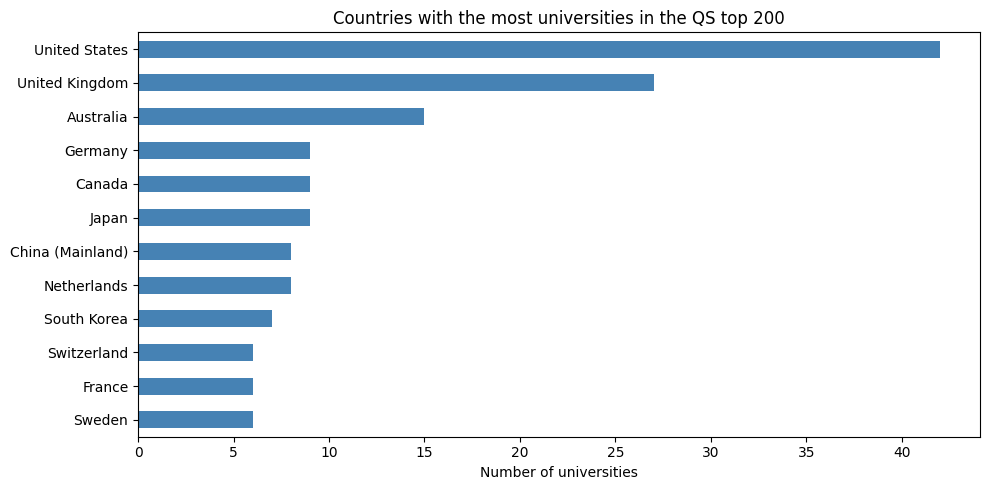

In [7]:
top200 = df[df["rank_num"] <= 200]
counts = top200["country"].value_counts().head(12)

counts.sort_values().plot.barh(color="steelblue")
plt.title("Countries with the most universities in the QS top 200")
plt.xlabel("Number of universities"); plt.ylabel("")
plt.tight_layout(); plt.show()

### Chart 2: Academic reputation vs employer reputation

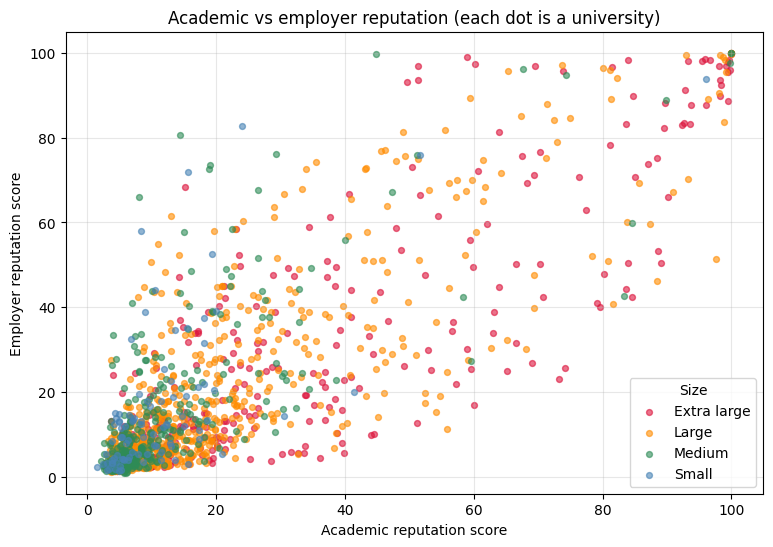

In [8]:
sub = df.dropna(subset=["ar_score", "er_score", "size_label"])
colors = {"Extra large": "crimson", "Large": "darkorange", "Medium": "seagreen", "Small": "steelblue"}

plt.figure(figsize=(9, 6))
for s, c in colors.items():
    d = sub[sub["size_label"] == s]
    plt.scatter(d["ar_score"], d["er_score"], s=18, alpha=0.6, color=c, label=s)
plt.title("Academic vs employer reputation (each dot is a university)")
plt.xlabel("Academic reputation score"); plt.ylabel("Employer reputation score")
plt.legend(title="Size"); plt.grid(alpha=0.3); plt.show()

### Chart 3: Overall score by university size

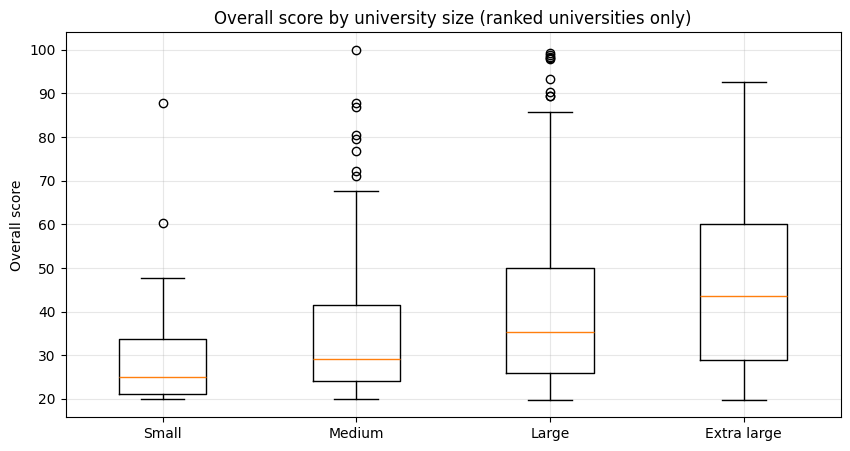

In [9]:
order = ["Small", "Medium", "Large", "Extra large"]
data = [df.loc[(df["size_label"] == s) & df["overall_score"].notna(), "overall_score"] for s in order]

plt.boxplot(data)
plt.xticks(range(1, len(order) + 1), order)
plt.title("Overall score by university size (ranked universities only)")
plt.ylabel("Overall score"); plt.grid(alpha=0.3); plt.show()

### Chart 4: Which metrics move together? (correlation heatmap)

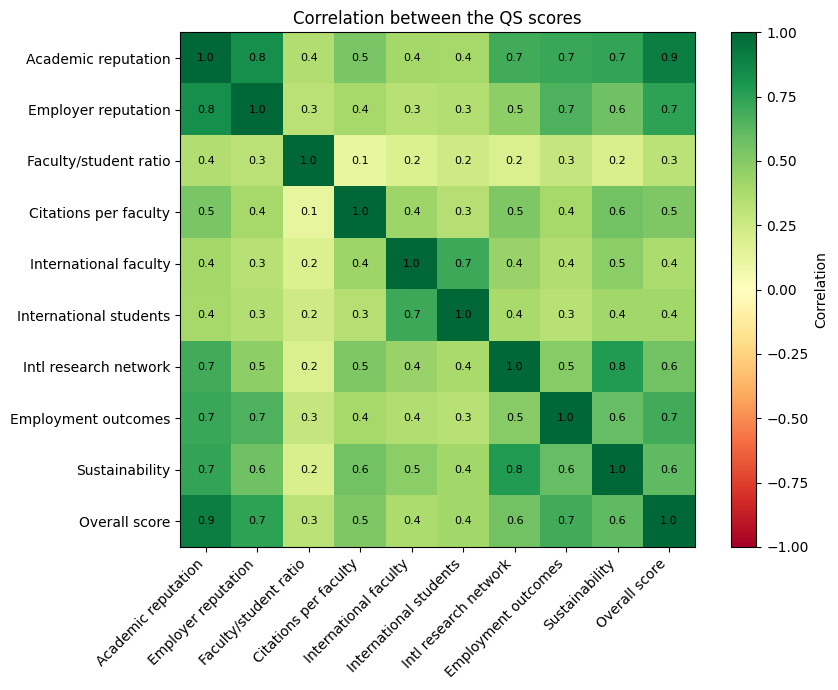

In [10]:
corr = df[metric_cols + ["overall_score"]].corr()
labels = [METRICS.get(c, "Overall score") for c in corr.columns]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="Correlation")
ax.set_title("Correlation between the QS scores")
plt.tight_layout(); plt.show()

## 4. The University Finder
Change the settings below, then run the cell. Every weight goes from 0 (do not care) to 10 (very important).
The **match score** is the weighted average of the metrics you care about. If a university has no score for a metric, that metric is left out for that university, and universities with too many missing metrics are removed.

In [11]:
# ---------------- YOUR SETTINGS ----------------
COUNTRIES = []                 # example: ["South Korea", "Japan"]   ([] means all countries)
SIZES     = []                 # example: ["Small", "Medium"]
FOCUS     = []                 # example: ["Full comprehensive"]
RESEARCH  = []                 # example: ["Very high", "High"]
MAX_RANK  = 500                # only universities ranked in the top N
TOP_N     = 10                 # how many results to show

WEIGHTS = {
    "ar_score":  8,   # academic reputation
    "er_score":  6,   # employer reputation
    "fsr_score": 7,   # faculty/student ratio (small classes)
    "cpf_score": 3,   # citations per faculty (research)
    "ifr_score": 2,   # international faculty
    "isr_score": 5,   # international students
    "irn_score": 2,   # international research network
    "ger_score": 6,   # employment outcomes
    "sus_score": 1,   # sustainability
}
# ------------------------------------------------

def find_universities(data, weights, countries=(), sizes=(), focus=(), research=(),
                      max_rank=500, top_n=10, min_coverage=0.6):
    pool = data[data["rank_num"] <= max_rank].copy()
    if countries: pool = pool[pool["country"].isin(countries)]
    if sizes:     pool = pool[pool["size_label"].isin(sizes)]
    if focus:     pool = pool[pool["focus_label"].isin(focus)]
    if research:  pool = pool[pool["research_label"].isin(research)]
    if pool.empty:
        return pool

    w = pd.Series(weights, dtype=float)
    scores = pool[w.index]
    has = scores.notna()
    num = (scores.fillna(0) * w).sum(axis=1)
    den = (has * w).sum(axis=1)

    pool["coverage"] = den / w.sum()
    pool["match_score"] = (num / den.replace(0, np.nan)).round(1)
    pool = pool[pool["coverage"] >= min_coverage]
    return pool.sort_values("match_score", ascending=False).head(top_n)

results = find_universities(df, WEIGHTS, COUNTRIES, SIZES, FOCUS, RESEARCH, MAX_RANK, TOP_N)

if results.empty:
    print("No universities match these settings. Try a larger MAX_RANK or fewer filters.")
else:
    show = results[["institution", "country", "rank_label", "size_label", "match_score"]]
    show.index = range(1, len(show) + 1)
    display(show)

,institution,country,rank_label,size_label,match_score
1,University of Oxford,United Kingdom,3,Large,98.9
2,University of Cambridge,United Kingdom,2,Large,98.8
3,Massachusetts Institute of Technology (MIT),United States,1,Medium,98.1
4,Imperial College London,United Kingdom,6,Large,96.0
5,Harvard University,United States,4,Large,94.7
6,Stanford University,United States,5,Large,93.5
7,Columbia University,United States,23,Extra large,92.3
8,Yale University,United States,16,Medium,92.0
9,University of Chicago,United States,11,Large,90.7
10,University of Pennsylvania,United States,12,Large,90.5


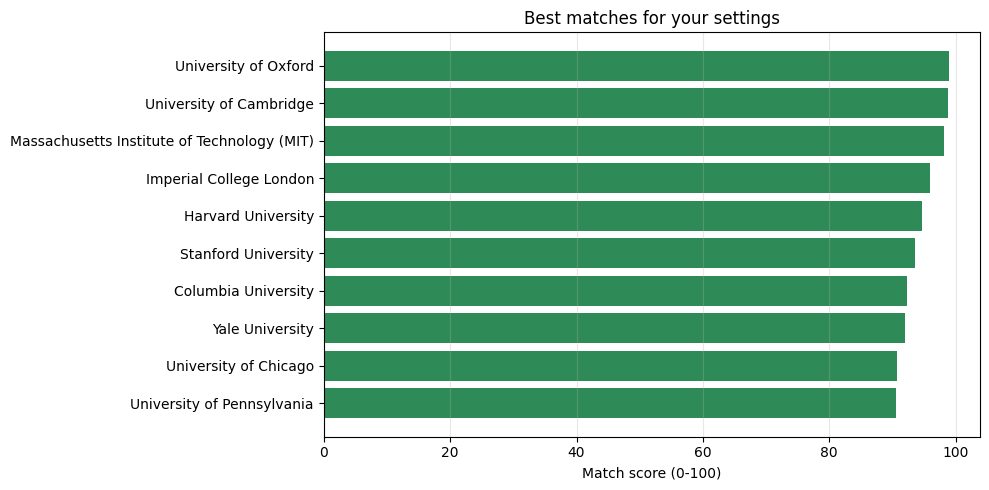

In [12]:
if not results.empty:
    r = results.sort_values("match_score")
    plt.figure(figsize=(10, 5))
    plt.barh(r["institution"].str.slice(0, 45), r["match_score"], color="seagreen")
    plt.title("Best matches for your settings")
    plt.xlabel("Match score (0-100)"); plt.grid(axis="x", alpha=0.3)
    plt.tight_layout(); plt.show()

### Chart 5: Compare your top 3 matches (radar chart)

/var/folders/zq/4sfqcvns48nc5xc7k_2f1rkw0000gn/T/ipykernel_3070/3187115465.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vals = row[metric_cols].fillna(0).astype(float).tolist()
/var/folders/zq/4sfqcvns48nc5xc7k_2f1rkw0000gn/T/ipykernel_3070/3187115465.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vals = row[metric_cols].fillna(0).astype(float).tolist()
/var/folders/zq/4sfqcvns48nc5xc7k_2f1rkw0000gn/T/ipykernel_3070/3187115465.py:10: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a

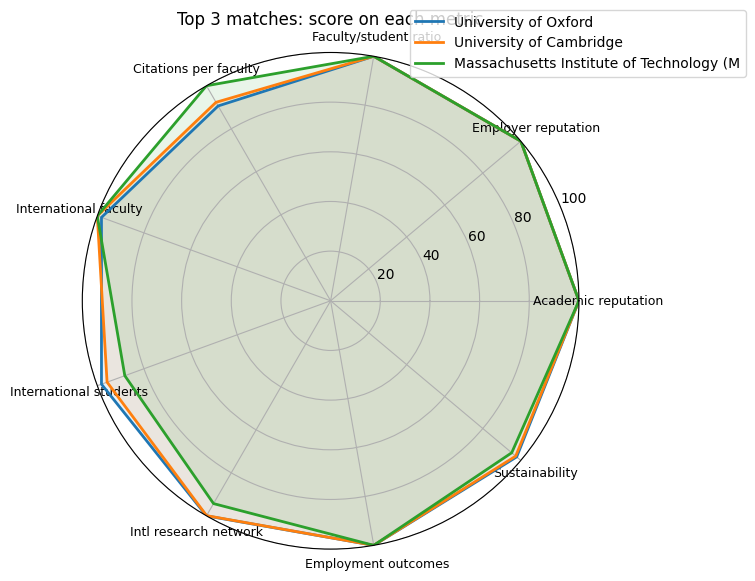

In [13]:
if len(results) >= 3:
    top3 = results.head(3)
    labels = [METRICS[c] for c in metric_cols]
    angles = np.linspace(0, 2 * np.pi, len(metric_cols), endpoint=False).tolist()
    angles += angles[:1]

    fig = plt.figure(figsize=(8, 8))
    ax = plt.subplot(111, polar=True)
    for _, row in top3.iterrows():
        vals = row[metric_cols].fillna(0).astype(float).tolist()
        vals += vals[:1]
        ax.plot(angles, vals, linewidth=2, label=row["institution"][:40])
        ax.fill(angles, vals, alpha=0.1)
    ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels, fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_title("Top 3 matches: score on each metric", pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
    plt.tight_layout(); plt.show()

## 5. Find universities similar to one you like
We turn each university into a list of its metric scores, standardise them, and use **cosine similarity** to find the universities with the most similar profile. Missing scores are filled with the median.

In [14]:
# ---------------- YOUR SETTINGS ----------------
LIKED = "Seoul National University"     # any part of a university name works
SIMILAR_N = 8
SIMILAR_COUNTRY = []                    # example: ["Japan", "China (Mainland)"]  ([] means anywhere)
# ------------------------------------------------

X = df[metric_cols].copy()
X = X.fillna(X.median())
Z = (X - X.mean()) / X.std()
Z = Z.fillna(0)

matches = df[df["institution"].str.contains(LIKED, case=False, regex=False)]
if matches.empty:
    print("No university found with that name. Try another word.")
else:
    idx = matches.index[0]
    print("Using:", df.loc[idx, "institution"], "|", df.loc[idx, "country"], "| rank", df.loc[idx, "rank_label"])

    v = Z.loc[idx].values
    sims = Z.values @ v / (np.linalg.norm(Z.values, axis=1) * np.linalg.norm(v) + 1e-9)

    out = df[["institution", "country", "rank_label", "size_label"]].copy()
    out["similarity"] = sims.round(3)
    out = out.drop(index=idx)
    if SIMILAR_COUNTRY:
        out = out[out["country"].isin(SIMILAR_COUNTRY)]
    out = out.sort_values("similarity", ascending=False).head(SIMILAR_N)
    out.index = range(1, len(out) + 1)
    display(out)

Using: Seoul National University | South Korea | rank 41


,institution,country,rank_label,size_label,similarity
1,The University of Tokyo,Japan,28,Large,0.981
2,Tsinghua University,China (Mainland),25,Extra large,0.970
3,Korea University,South Korea,79,Large,0.968
4,Peking University,China (Mainland),=17,Extra large,0.961
5,Princeton University,United States,=17,Medium,0.955
6,National Taiwan University (NTU),Taiwan,69,Extra large,0.948
7,Yonsei University,South Korea,=76,Large,0.941
8,Kyoto University,Japan,46,Large,0.931


## 6. Is it worth going to a top-ranked university? Rank vs. quality of student life
A quick look at whether top-ranked universities also have small classes (faculty/student ratio) and many international students.

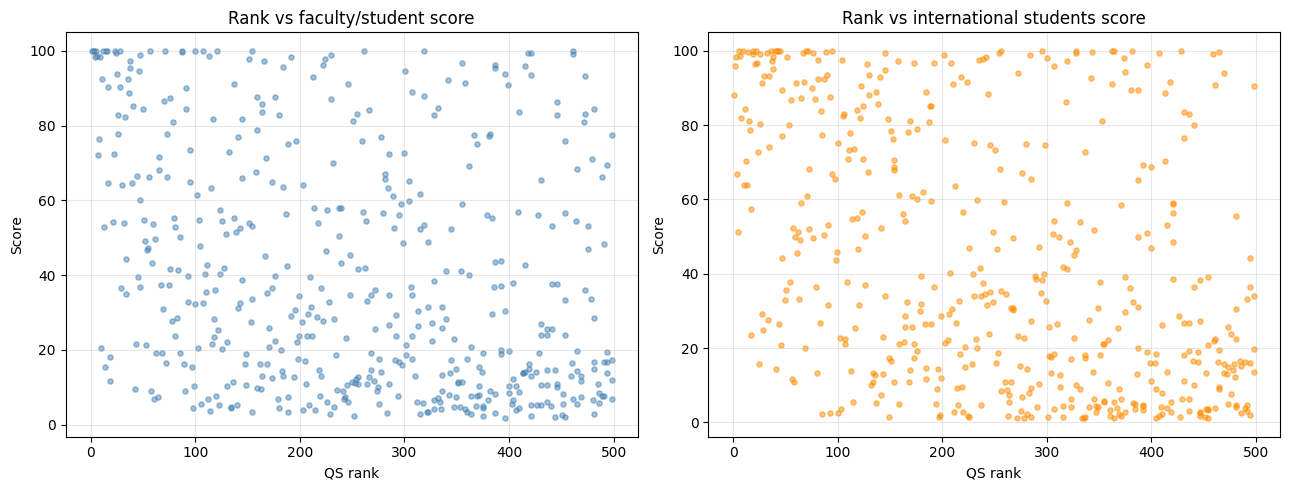

Correlation of rank with faculty/student score: -0.31
Correlation of rank with international students score: -0.41


In [15]:
sub = df[(df["rank_num"] <= 500)].dropna(subset=["fsr_score", "isr_score"])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(sub["rank_num"], sub["fsr_score"], s=14, alpha=0.5, color="steelblue")
ax[0].set_title("Rank vs faculty/student score"); ax[0].set_xlabel("QS rank"); ax[0].set_ylabel("Score")
ax[1].scatter(sub["rank_num"], sub["isr_score"], s=14, alpha=0.5, color="darkorange")
ax[1].set_title("Rank vs international students score"); ax[1].set_xlabel("QS rank"); ax[1].set_ylabel("Score")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Correlation of rank with faculty/student score: %.2f" % sub["rank_num"].corr(sub["fsr_score"]))
print("Correlation of rank with international students score: %.2f" % sub["rank_num"].corr(sub["isr_score"]))

## 7. Findings
*Replace the text below with your own results after you run the notebook.*

1. The country with the most universities in the top 200 is ___, followed by ___ and ___.
2. For my settings (___), the best match is ___, followed by ___ and ___.
3. Academic reputation and employer reputation are (strongly / weakly) related (correlation about ___).
4. Universities most similar to ___ are ___ and ___.
5. A higher rank (does / does not) mean smaller classes or more international students.

## 8. About the data and limits
- **Source:** QS World University Rankings 2024, official results table (Excel), Quacquarelli Symonds. https://www.topuniversities.com/world-university-rankings
- **Size:** 1,498 universities, 104 countries, 9 indicator scores plus overall score.
- **Cleaning:** checked for duplicate names (none found), converted text ranks (`=76`, `1001-1200`, `1401+`) to numbers, turned `-` into missing values, turned codes into readable labels, kept only the useful columns.
- **Limits:**
  - Only about 600 universities have an overall score, but many more have indicator scores, so the finder uses the indicators.
  - Missing indicators are left out for that university, so a match score is an average of fewer metrics.
  - QS rankings measure reputation and research more than teaching quality, and they depend on QS's own method.
  - Mongolian universities do not appear in this table, so Mongolia cannot be searched here.